Lorenz 1963 Model:
sigma = Prandtl Number
r = Rayleigh Number
b = ratio of scale of convection

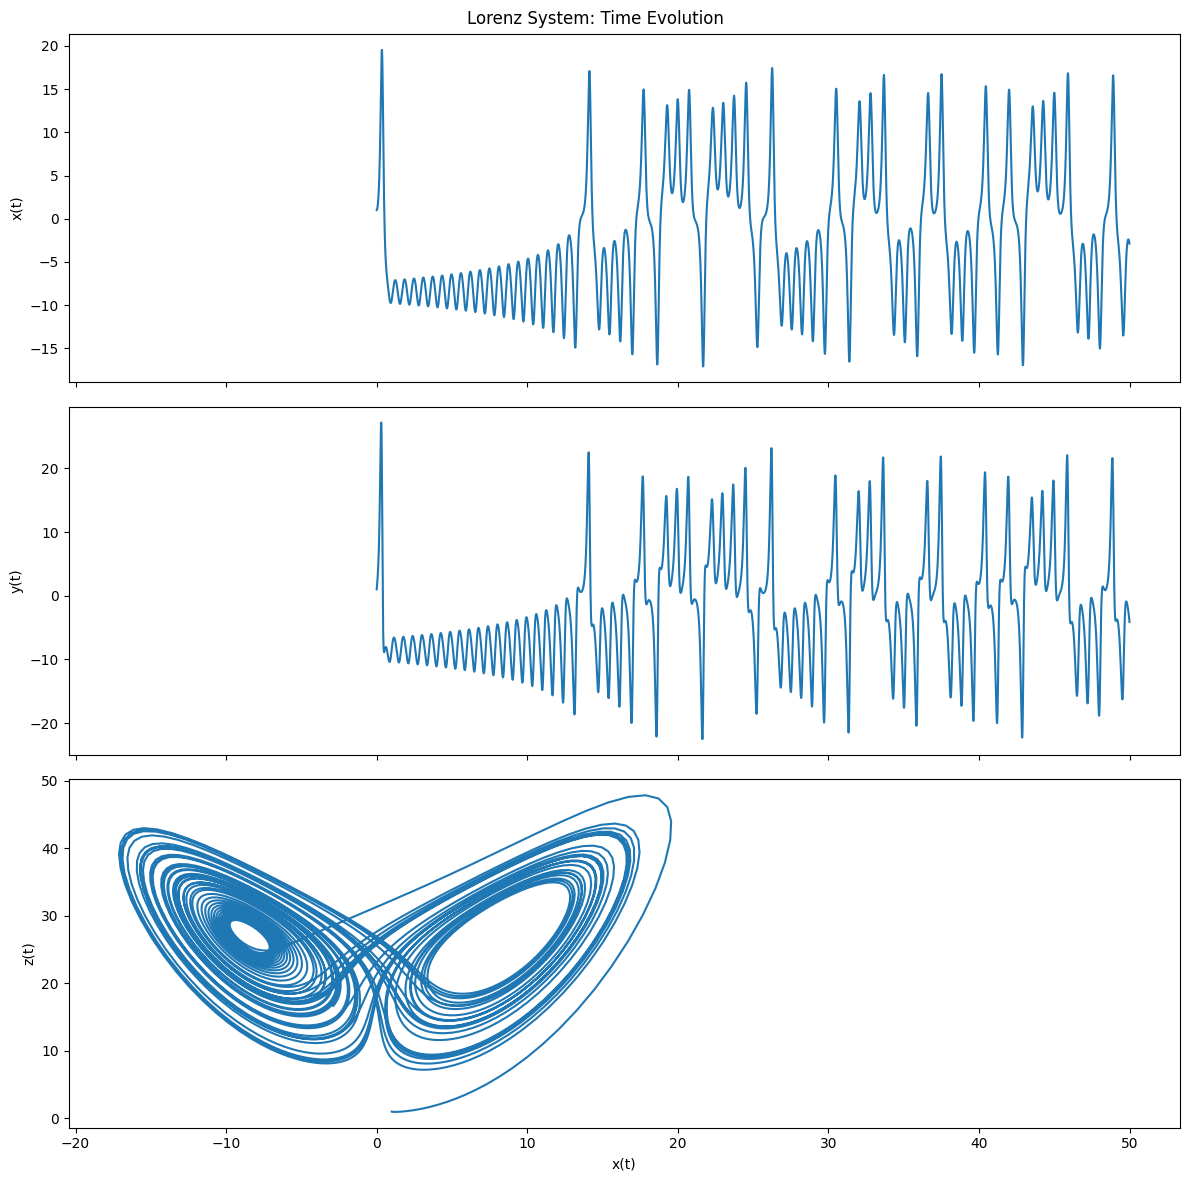

In [10]:

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

sigma = 10
r = 28
b = 8/3

def lorenz(t, xyz):
    x, y, z = xyz
    return [
        sigma * (y - x),
        r * x - y - x * z,
        x * y - b * z
    ]

t = np.arange(0, 50, 0.01)

sol = solve_ivp(
    lorenz,
    [0, 50],
    [1, 1, 1],
    t_eval=t,
    rtol=1e-8,
    atol=1e-10
)

if not sol.success:
    raise RuntimeError(sol.message)

x, y, z = sol.y

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

axes[0].plot(sol.t, x)
axes[0].set_ylabel("x(t)")

axes[1].plot(sol.t, y)
axes[1].set_ylabel("y(t)")

axes[2].plot(x, z)
axes[2].set_ylabel("z(t)")
axes[2].set_xlabel("x(t)")

fig.suptitle("Lorenz System: Time Evolution")
plt.tight_layout()
plt.show()


# The Lorenz 1996 (L96) Atmospheric Model & Diagnostic Formulations
(The equations are written by Gemini)

## 1. Overview and Physical Motivation
Introduced by Edward Lorenz in 1996, the **Lorenz 1996 model** serves as a core dynamical testbed for Numerical Weather Prediction (NWP), spatial data assimilation (DA), and predictability studies. 

Unlike the 0D spectral mode models (Lorenz 1963 and 1984), Lorenz 1996 features an **explicit spatial grid** representing atmospheric variables (such as mid-tropospheric vorticity, temperature, or geopotential height anomaly) at $K$ discrete, equally spaced longitudinal sectors along a mid-latitude parallel circle (typically $K = 40$ at $45^\circ\text{N}$).

---

## 2. Governing Equations

### 2.1 Single-Scale Lorenz 1996 Model
The time evolution of the atmospheric state vector $\mathbf{X} = [X_1, X_2, \dots, X_K]^T$ is governed by:

$$\frac{dX_k}{dt} = \underbrace{(X_{k+1} - X_{k-2})X_{k-1}}_{\text{Nonlinear Advection}} - \underbrace{X_k}_{\text{Linear Damping}} + \underbrace{F}_{\text{External Forcing}}$$

with cyclic boundary conditions:
$$X_{-1} = X_{K-1}, \quad X_0 = X_K, \quad X_{K+1} = X_1, \quad X_{K+2} = X_2$$

* **Nonlinear Advection:** Mimics the advective transport of vorticity/momentum by large-scale winds. Crucially, it satisfies the conservation of total kinetic energy $E = \frac{1}{2}\sum_{k=1}^K X_k^2$:
  $$\sum_{k=1}^K (X_{k+1} - X_{k-2})X_{k-1}X_k = 0$$
* **Linear Damping ($-X_k$):** Represents mechanical boundary-layer friction and radiative thermal dissipation.
* **External Thermal Forcing ($F$):** Mimics the equator-to-pole solar insolation gradient (standard chaotic regime: $F = 8.0$).
* **Atmospheric Scaling:** $1 \text{ model time unit} \approx 5 \text{ atmospheric days}$ ($\Delta t = 0.01 \approx 1.2 \text{ hours}$).

---

### 2.2 Two-Scale Coupled Lorenz 1996 Model (Multiscale Formulation)
To resolve sub-grid convective-scale motions (e.g., thunderstorms) coupled to slow planetary waves:

$$\frac{dX_k}{dt} = (X_{k+1} - X_{k-2})X_{k-1} - X_k + F - \frac{h\,c}{b} \sum_{j=1}^J Y_{j,k}$$

$$\frac{dY_{j,k}}{dt} = c\,b\,Y_{j+1,k}(Y_{j-1,k} - Y_{j+2,k}) - c\,Y_{j,k} + \frac{h\,c}{b} X_k$$

where:
* $X_k$ ($k = 1, \dots, K$): Slow, large-scale synoptic variables.
* $Y_{j,k}$ ($j = 1, \dots, J$): Fast, small-scale convective variables associated with synoptic node $k$.
* $c$: Time-scale ratio ($c = 10 \implies Y$ evolves 10 times faster than $X$).
* $b$: Spatial amplitude scale ratio ($b = 10 \implies Y$ has 10 times smaller amplitude than $X$).
* $h$: Cross-scale coupling parameter ($h = 1.0$).

---

## 3. Mathematical Formulations for Figure Calculations

### 3.1 Numerical Integration (4th-Order Runge-Kutta / RK4)
For a system $\frac{d\mathbf{X}}{dt} = \mathbf{f}(\mathbf{X})$ with time step $\Delta t$:

$$\mathbf{k}_1 = \mathbf{f}(\mathbf{X}_n)$$

$$\mathbf{k}_2 = \mathbf{f}\left(\mathbf{X}_n + \frac{\Delta t}{2}\mathbf{k}_1\right)$$

$$\mathbf{k}_3 = \mathbf{f}\left(\mathbf{X}_n + \frac{\Delta t}{2}\mathbf{k}_2\right)$$

$$\mathbf{k}_4 = \mathbf{f}\left(\mathbf{X}_n + \Delta t\,\mathbf{k}_3\right)$$

$$\mathbf{X}_{n+1} = \mathbf{X}_n + \frac{\Delta t}{6}(\mathbf{k}_1 + 2\mathbf{k}_2 + 2\mathbf{k}_3 + \mathbf{k}_4)$$

---

### 3.2 Lyapunov Exponent Spectrum (Benettin QR Algorithm)
To compute the rate of separation of infinitesimal perturbations, we track the tangent linear system:

$$\frac{d(\delta \mathbf{X})}{dt} = \mathbf{J}(\mathbf{X}(t))\,\delta \mathbf{X}$$

where the analytical spatial Jacobian matrix $\mathbf{J}(\mathbf{X}) \in \mathbb{R}^{K \times K}$ has non-zero entries:

$$J_{i,j} = \frac{\partial f_i}{\partial X_j} = \begin{cases} 
-1 & \text{if } j = i \\
X_{i-1} & \text{if } j \equiv (i + 1) \pmod K \\
-X_{i-1} & \text{if } j \equiv (i - 2) \pmod K \\
X_{i+1} - X_{i-2} & \text{if } j \equiv (i - 1) \pmod K \\
0 & \text{otherwise}
\end{cases}$$

An orthonormal basis $\mathbf{Q}(t) \in \mathbb{R}^{K \times K}$ is integrated along the trajectory and periodically re-orthonormalized via QR decomposition ($\mathbf{Q}_{n} = \mathbf{Q}_{n+1}' \mathbf{R}_{n+1}$):

$$\lambda_i = \lim_{T \to \infty} \frac{1}{T} \sum_{n=1}^{N_{\text{steps}}} \ln |R_{ii}^{(n)}|$$

#### Kaplan-Yorke (Lyapunov) Attractor Dimension $D_{KY}$:
$$D_{KY} = j + \frac{\sum_{i=1}^j \lambda_i}{|\lambda_{j+1}|}$$

where $j$ is the largest index for which $\sum_{i=1}^j \lambda_i \ge 0$.

---

### 3.3 Poincaré Section for Bifurcation Diagram
To convert the continuous-time ODE into a discrete bifurcation map across the parameter sweep $F \in [0, 10]$, we capture the local maxima of the first coordinate $X_1(t)$:

$$\Sigma = \left\{ \mathbf{X} \in \mathbb{R}^K \;\middle|\; \frac{dX_1}{dt} = 0, \quad \frac{d^2X_1}{dt^2} < 0 \right\}$$

---

### 3.4 Root Mean Square Error (RMSE) & Climatological Saturation
Given a true atmospheric trajectory $\mathbf{X}^{\text{true}}(t)$ and an ensemble/perturbed forecast $\mathbf{X}^{(m)}(t)$:

$$\text{RMSE}(t) = \sqrt{\frac{1}{K} \sum_{k=1}^K \left( X_k^{(m)}(t) - X_k^{\text{true}}(t) \right)^2}$$

* **Initial Exponential Growth Phase:** $\text{RMSE}(t) \approx \epsilon_0 \exp(\lambda_{\max} t)$
* **Error Doubling Time:** $T_d = \frac{\ln(2)}{\lambda_{\max}} \approx 2.1 \text{ days}$ (at $F=8.0$)
* **Predictability Horizon:** $T_{\text{pred}} \approx \frac{1}{\lambda_{\max}} \ln\left(\frac{E_{\text{crit}}}{\epsilon_0}\right) = -\frac{1}{\lambda_{\max}} \ln(\epsilon_0) + \text{const}$
* **Climatological Saturation Ceiling:** For two completely uncorrelated states $\mathbb{E}[X Y] = 0$:
  $$\text{RMSE}_{\text{sat}} = \sqrt{\mathbb{E}[(X - Y)^2]} = \sqrt{\sigma^2 + \sigma^2} = \sqrt{2}\,\sigma_{\text{clim}}$$

---

### 3.5 Operational Forecast Skill Metrics
* **Ensemble Mean State:**
  $$\bar{X}_k(t) = \frac{1}{M} \sum_{m=1}^M X_k^{(m)}(t)$$

* **Anomaly Correlation Coefficient (ACC):**
  $$\text{ACC}(t) = \frac{\sum_{k=1}^K (X_k^{\text{fcst}}(t) - \bar{X}_{\text{clim}})(X_k^{\text{true}}(t) - \bar{X}_{\text{clim}})}{\sqrt{\sum_{k=1}^K (X_k^{\text{fcst}}(t) - \bar{X}_{\text{clim}})^2} \sqrt{\sum_{k=1}^K (X_k^{\text{true}}(t) - \bar{X}_{\text{clim}})^2}}$$
  *(Operational skill threshold: $\text{ACC} \ge 0.6$)*

* **Spatial Autocorrelation Function:**
  $$r(L) = \frac{\frac{1}{T \cdot K} \sum_{t=1}^T \sum_{k=1}^K X'_k(t) \cdot X'_{(k+L) \pmod K}(t)}{\sigma_X^2}, \quad L \in \left[0, \frac{K}{2}\right]$$
  where $X'_k(t) = X_k(t) - \bar{X}_k$. The first negative trough identifies the half-wavelength $\frac{\lambda_{\text{wave}}}{2}$, yielding the planetary wavenumber $m = \frac{K}{\lambda_{\text{wave}}}$.

Computing Lyapunov spectrum for K = 20...
Computing Lyapunov spectrum for K = 40...
Computing Lyapunov spectrum for K = 60...


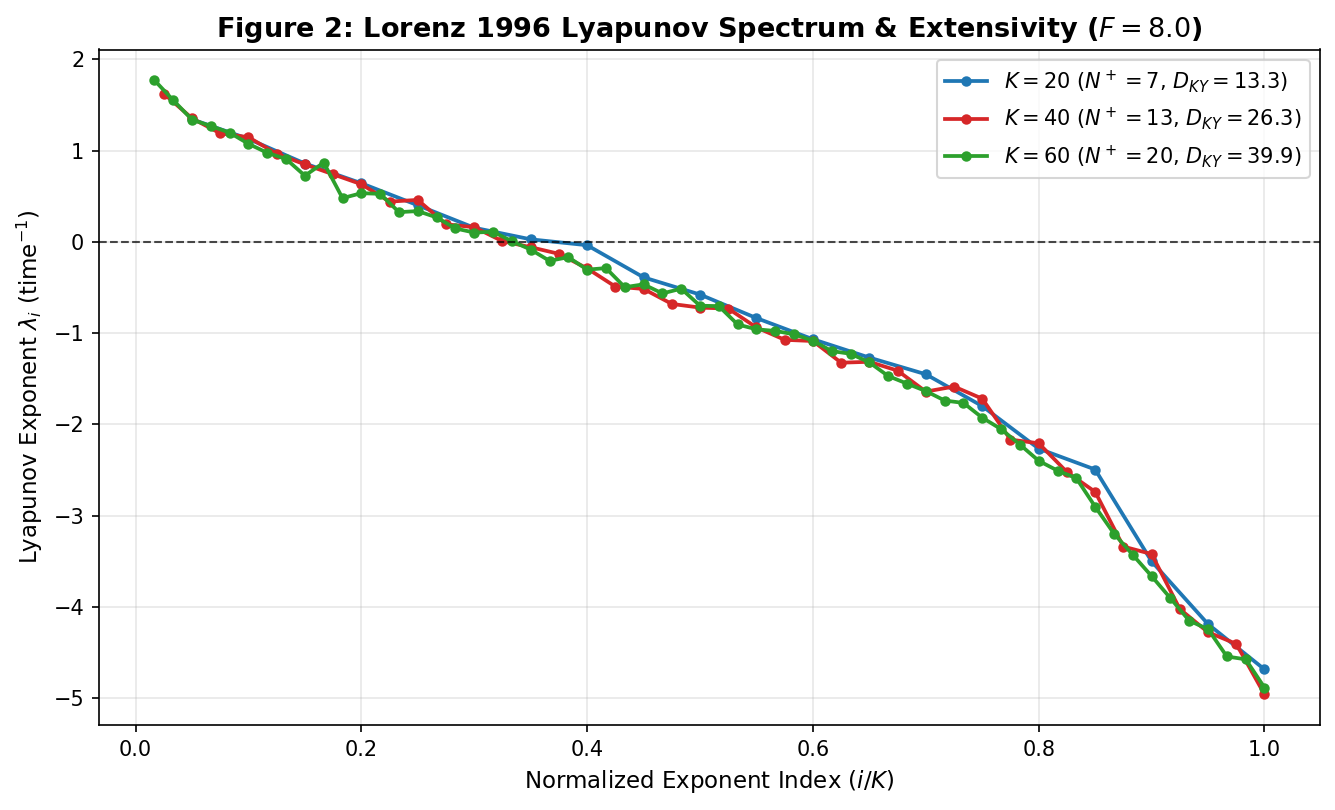

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def l96_rhs(x, F):
    """Vectorized RHS of the single-scale Lorenz 1996 model."""
    return (np.roll(x, -1) - np.roll(x, 2)) * np.roll(x, 1) - x + F

def l96_jacobian(x):
    """Exact analytical Jacobian matrix J_ij = d(f_i)/d(x_j) for Lorenz 1996."""
    K = len(x)
    J = -np.eye(K)
    for i in range(K):
        J[i, (i + 1) % K] += x[(i - 1) % K]
        J[i, (i - 2) % K] -= x[(i - 1) % K]
        J[i, (i - 1) % K] += x[(i + 1) % K] - x[(i - 2) % K]
    return J

def rk4_step_with_tangent(x, Q, dt, F):
    """Simultaneously integrates the state x and tangent vectors Q via RK4."""
    def f_both(state, tangent):
        dx = l96_rhs(state, F)
        dQ = l96_jacobian(state) @ tangent
        return dx, dQ

    k1_x, k1_Q = f_both(x, Q)
    k2_x, k2_Q = f_both(x + 0.5 * dt * k1_x, Q + 0.5 * dt * k1_Q)
    k3_x, k3_Q = f_both(x + 0.5 * dt * k2_x, Q + 0.5 * dt * k2_Q)
    k4_x, k4_Q = f_both(x + dt * k3_x, Q + dt * k3_Q)

    x_next = x + (dt / 6.0) * (k1_x + 2*k2_x + 2*k3_x + k4_x)
    Q_next = Q + (dt / 6.0) * (k1_Q + 2*k2_Q + 2*k3_Q + k4_Q)
    return x_next, Q_next

def compute_lyapunov_spectrum(K=40, F=8.0, dt=0.01, spinup_steps=1000, calc_steps=4000, qr_interval=5):
    # Initialize state and spin up onto the attractor
    x = F * np.ones(K)
    x[0] += 0.01
    for _ in range(spinup_steps):
        k1 = l96_rhs(x, F)
        k2 = l96_rhs(x + 0.5*dt*k1, F)
        k3 = l96_rhs(x + 0.5*dt*k2, F)
        k4 = l96_rhs(x + dt*k3, F)
        x = x + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

    # Initialize orthonormal tangent basis Q
    Q = np.eye(K)
    lyap_sum = np.zeros(K)
    total_time = 0.0

    for step in range(1, calc_steps + 1):
        x, Q = rk4_step_with_tangent(x, Q, dt, F)
        if step % qr_interval == 0:
            Q, R = np.linalg.qr(Q)
            lyap_sum += np.log(np.abs(np.diag(R)))
            total_time += qr_interval * dt

    spectrum = lyap_sum / total_time
    # Compute Kaplan-Yorke Dimension D_KY
    cumsum = np.cumsum(spectrum)
    j = np.where(cumsum >= 0)[0][-1]
    d_ky = (j + 1) + cumsum[j] / np.abs(spectrum[j + 1])
    return spectrum, d_ky

# --- Run and Plot Figure 2 ---
plt.figure(figsize=(9, 5.5), dpi=150)
colors = ['#1f77b4', '#d62728', '#2ca02c']

for K, col in zip([20, 40, 60], colors):
    print(f"Computing Lyapunov spectrum for K = {K}...")
    spec, d_ky = compute_lyapunov_spectrum(K=K, F=8.0)
    norm_idx = np.arange(1, K + 1) / K
    n_pos = np.sum(spec > 0)
    plt.plot(norm_idx, spec, marker='o', markersize=4, color=col, lw=1.8,
             label=f"$K={K}$ ($N^+={n_pos}$, $D_{{KY}}={d_ky:.1f}$)")

plt.axhline(0, color='black', linestyle='--', lw=1, alpha=0.7)
plt.title("Figure 2: Lorenz 1996 Lyapunov Spectrum & Extensivity ($F = 8.0$)", fontsize=13, fontweight='bold')
plt.xlabel("Normalized Exponent Index ($i / K$)", fontsize=11)
plt.ylabel("Lyapunov Exponent $\\lambda_i$ ($\\text{time}^{-1}$)", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
# plt.savefig("Figure2_L96_Lyapunov_Spectrum.png")
plt.show()

Sweeping forcing parameter F for Bifurcation Diagram and Max Lyapunov Exponent...


Processing F values: 100%|██████████| 10/10 [00:04<00:00,  2.42it/s]


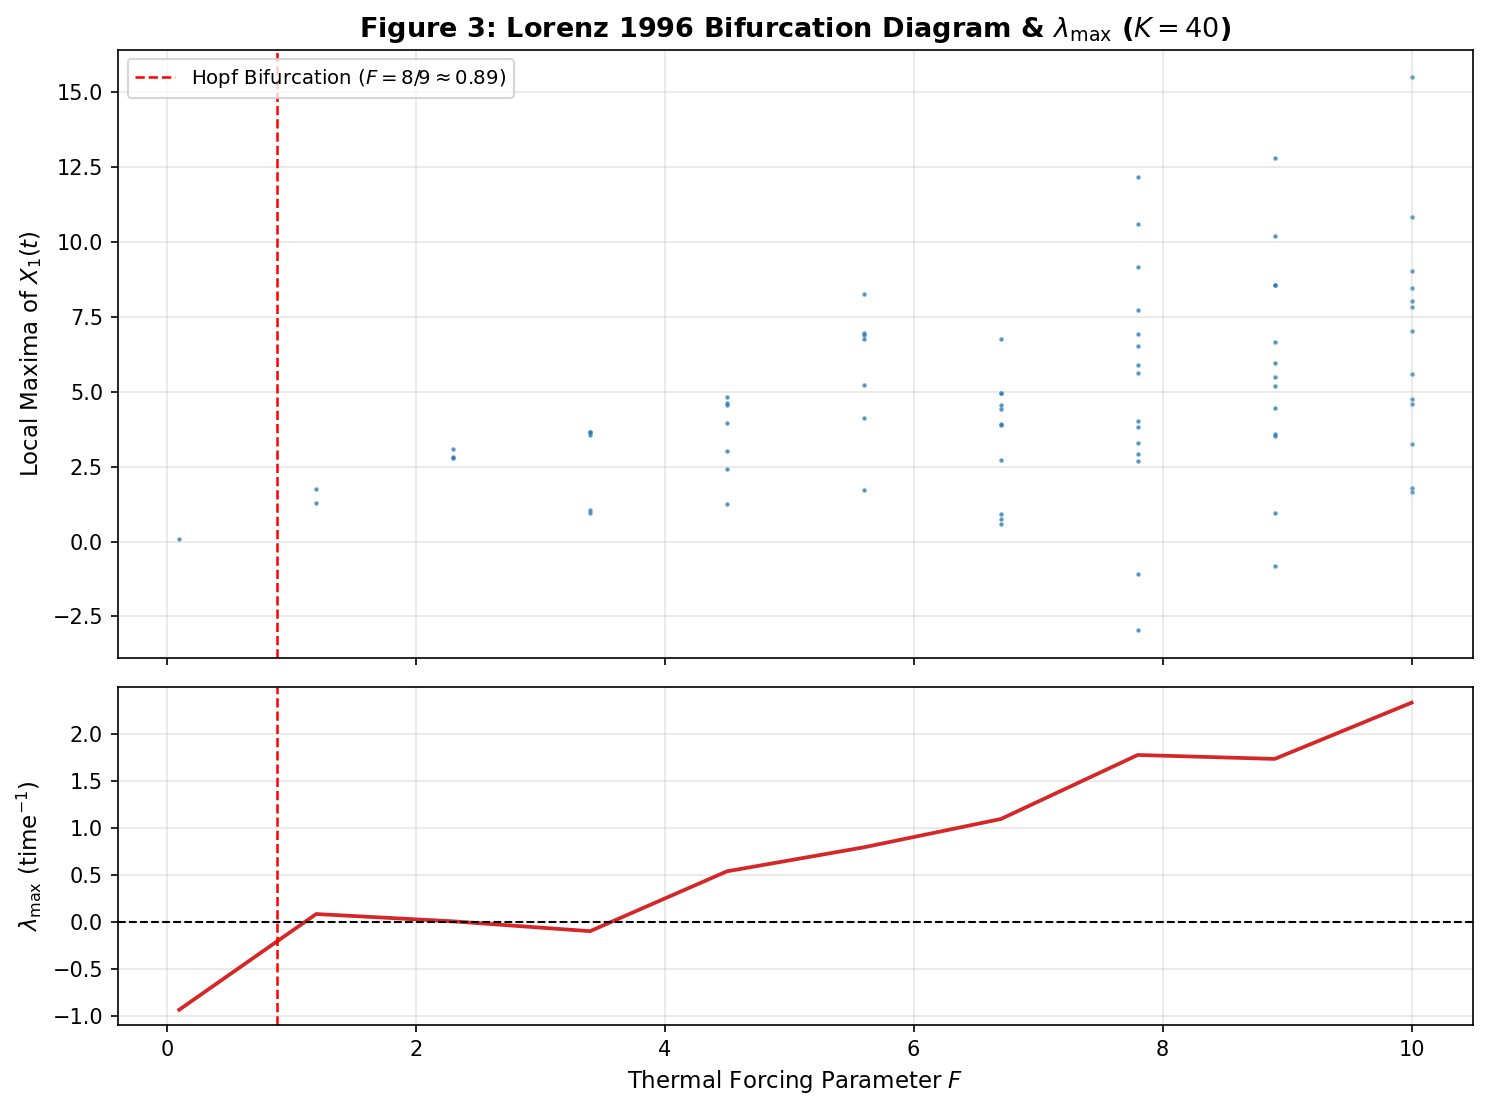

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema
from tqdm import tqdm

def l96_rk4_step(x, dt, F):
    def rhs(s):
        return (np.roll(s, -1) - np.roll(s, 2)) * np.roll(s, 1) - s + F
    k1 = rhs(x)
    k2 = rhs(x + 0.5 * dt * k1)
    k3 = rhs(x + 0.5 * dt * k2)
    k4 = rhs(x + dt * k3)
    return x + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

K = 40
dt = 0.02
F_values = np.linspace(0.1, 10.0, 10)

bif_F = []
bif_maxima = []
max_lyap = []

print("Sweeping forcing parameter F for Bifurcation Diagram and Max Lyapunov Exponent...")
for F in tqdm(F_values, desc="Processing F values"):
    # Initialize with slight perturbation
    x = F * np.ones(K)
    x[0] += 0.05
    
    # Spin-up to settle onto attractor
    for _ in range(500):
        x = l96_rk4_step(x, dt, F)
    
    # Track trajectory of X_0 and tangent vector for largest Lyapunov exponent
    x0_series = np.zeros(500)
    v = np.random.randn(K)
    v /= np.linalg.norm(v)
    lyap_sum = 0.0
    eps = 1e-7
    
    for step in range(500):
        x_pert = x + eps * v
        x = l96_rk4_step(x, dt, F)
        x_pert = l96_rk4_step(x_pert, dt, F)
        
        diff = (x_pert - x) / eps
        norm_diff = np.linalg.norm(diff)
        lyap_sum += np.log(norm_diff)
        v = diff / norm_diff
        x0_series[step] = x[0]
        
    max_lyap.append(lyap_sum / (500 * dt))
    
    # Extract local maxima of X_0(t)
    max_idx = argrelextrema(x0_series, np.greater)[0]
    if len(max_idx) == 0 or np.std(x0_series) < 1e-4:
        bif_F.append(F)
        bif_maxima.append(x0_series[-1])
    else:
        for idx in max_idx[:40]:  # Cap points per F for clean plotting
            bif_F.append(F)
            bif_maxima.append(x0_series[idx])

# --- Plot Figure 3 ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, dpi=150,
                               gridspec_kw={'height_ratios': [1.8, 1]})

# Top Panel: Bifurcation Diagram
ax1.scatter(bif_F, bif_maxima, s=1.5, color='#1f77b4', alpha=0.6)
ax1.axvline(8/9, color='red', linestyle='--', lw=1.2, label='Hopf Bifurcation ($F = 8/9 \\approx 0.89$)')
ax1.set_ylabel("Local Maxima of $X_1(t)$", fontsize=11)
ax1.set_title("Figure 3: Lorenz 1996 Bifurcation Diagram & $\\lambda_{\\max}$ ($K = 40$)", fontsize=13, fontweight='bold')
ax1.legend(loc='upper left', fontsize=9.5)
ax1.grid(True, alpha=0.3)

# Bottom Panel: Maximum Lyapunov Exponent
ax2.plot(F_values, max_lyap, color='#d62728', lw=1.8)
ax2.axhline(0, color='black', linestyle='--', lw=1)
ax2.axvline(8/9, color='red', linestyle='--', lw=1.2)
ax2.set_xlabel("Thermal Forcing Parameter $F$", fontsize=11)
ax2.set_ylabel("$\\lambda_{\\max}$ ($\\text{time}^{-1}$)", fontsize=11)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig("Figure3_L96_Bifurcation_Diagram.png")
plt.show()

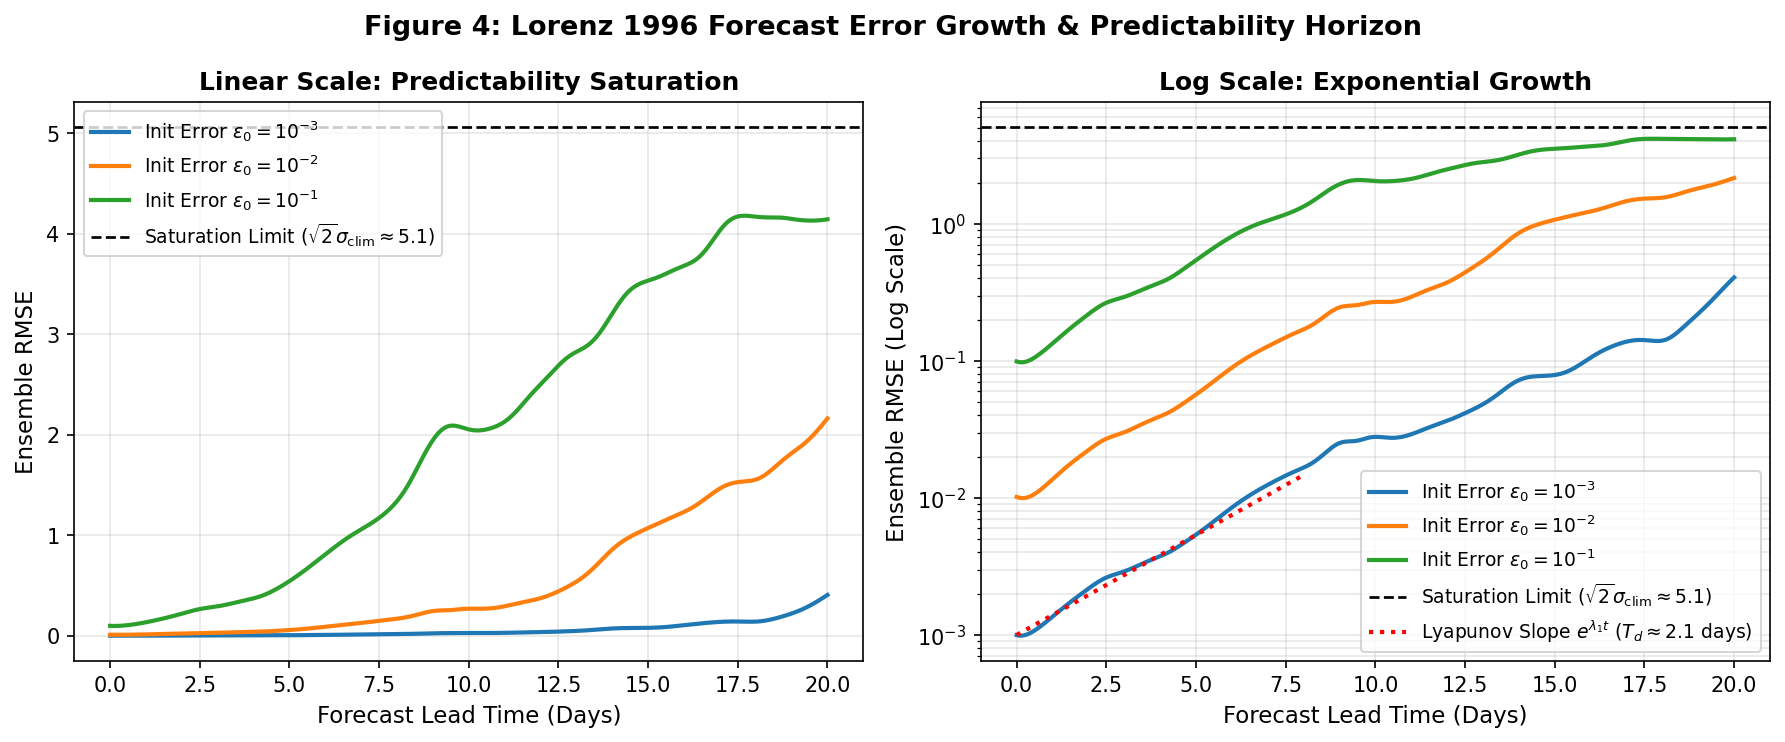

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def l96_rk4_batch(X, dt, F=8.0):
    """Vectorized RK4 step for a 2D array X of shape (n_members, K)."""
    def rhs(s):
        return (np.roll(s, -1, axis=-1) - np.roll(s, 2, axis=-1)) * np.roll(s, 1, axis=-1) - s + F
    k1 = rhs(X)
    k2 = rhs(X + 0.5 * dt * k1)
    k3 = rhs(X + 0.5 * dt * k2)
    k4 = rhs(X + dt * k3)
    return X + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

K = 40
F = 8.0
dt = 0.01          # 0.01 model units = 0.05 days = 1.2 hours
n_steps = 400      # 4.0 model units = 20 Forecast Days
n_ensemble = 100
days = np.arange(n_steps + 1) * dt * 5.0  # 1 time unit = 5 days

# Spin up a true state trajectory on the attractor
np.random.seed(42)
x_init = F * np.ones((1, K))
x_init[0, 0] += 0.01
for _ in range(2000):
    x_init = l96_rk4_batch(x_init, dt, F)

# Compute true reference trajectory
true_traj = np.zeros((n_steps + 1, K))
true_traj[0] = x_init[0]
curr = x_init.copy()
for t in range(1, n_steps + 1):
    curr = l96_rk4_batch(curr, dt, F)
    true_traj[t] = curr[0]

# Climatological saturation limit: sqrt(2) * std(X)
sigma_clim = np.std(true_traj)
saturation_limit = np.sqrt(2) * sigma_clim

# --- Run Ensemble Perturbations ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=150)
eps_list = [1e-3, 1e-2, 1e-1]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for eps, col in zip(eps_list, colors):
    # Initialize ensemble around true state at t=0
    ens = np.repeat(x_init, n_ensemble, axis=0) + np.random.normal(0, eps, size=(n_ensemble, K))
    rmse_curve = np.zeros(n_steps + 1)
    rmse_curve[0] = np.sqrt(np.mean((ens - true_traj[0])**2))
    
    for t in range(1, n_steps + 1):
        ens = l96_rk4_batch(ens, dt, F)
        rmse_curve[t] = np.sqrt(np.mean((ens - true_traj[t])**2))
        
    ax1.plot(days, rmse_curve, color=col, lw=2, label=f"Init Error $\\epsilon_0 = 10^{{{int(np.log10(eps))}}}$")
    ax2.semilogy(days, rmse_curve, color=col, lw=2, label=f"Init Error $\\epsilon_0 = 10^{{{int(np.log10(eps))}}}$")

# Reference lines
for ax in (ax1, ax2):
    ax.axhline(saturation_limit, color='black', linestyle='--', lw=1.3,
               label=f"Saturation Limit ($\\sqrt{{2}}\\sigma_{{\\text{{clim}}}} \\approx {saturation_limit:.1f}$)")
    ax.set_xlabel("Forecast Lead Time (Days)", fontsize=11)
    ax.grid(True, which="both", alpha=0.3)

# Theoretical exponential slope on log plot (lambda_1 ~ 1.68 time^-1 = 0.336 day^-1)
t_ref = np.linspace(0, 8, 50)
ax2.semilogy(t_ref, 1e-3 * np.exp(0.336 * t_ref), 'r:', lw=2, label="Lyapunov Slope $e^{\\lambda_1 t}$ ($T_d \\approx 2.1$ days)")

ax1.set_title("Linear Scale: Predictability Saturation", fontsize=12, fontweight='bold')
ax1.set_ylabel("Ensemble RMSE", fontsize=11)
ax1.legend(fontsize=9)

ax2.set_title("Log Scale: Exponential Growth", fontsize=12, fontweight='bold')
ax2.set_ylabel("Ensemble RMSE (Log Scale)", fontsize=11)
ax2.legend(fontsize=9, loc='lower right')

fig.suptitle("Figure 4: Lorenz 1996 Forecast Error Growth & Predictability Horizon", fontsize=13, fontweight='bold')
plt.tight_layout()
# plt.savefig("Figure4_L96_RMSE_Saturation.png")
plt.show()

Spinning up Two-Scale Coupled Lorenz 1996 model...
Simulating upscale error cascade from convective Y to synoptic X...


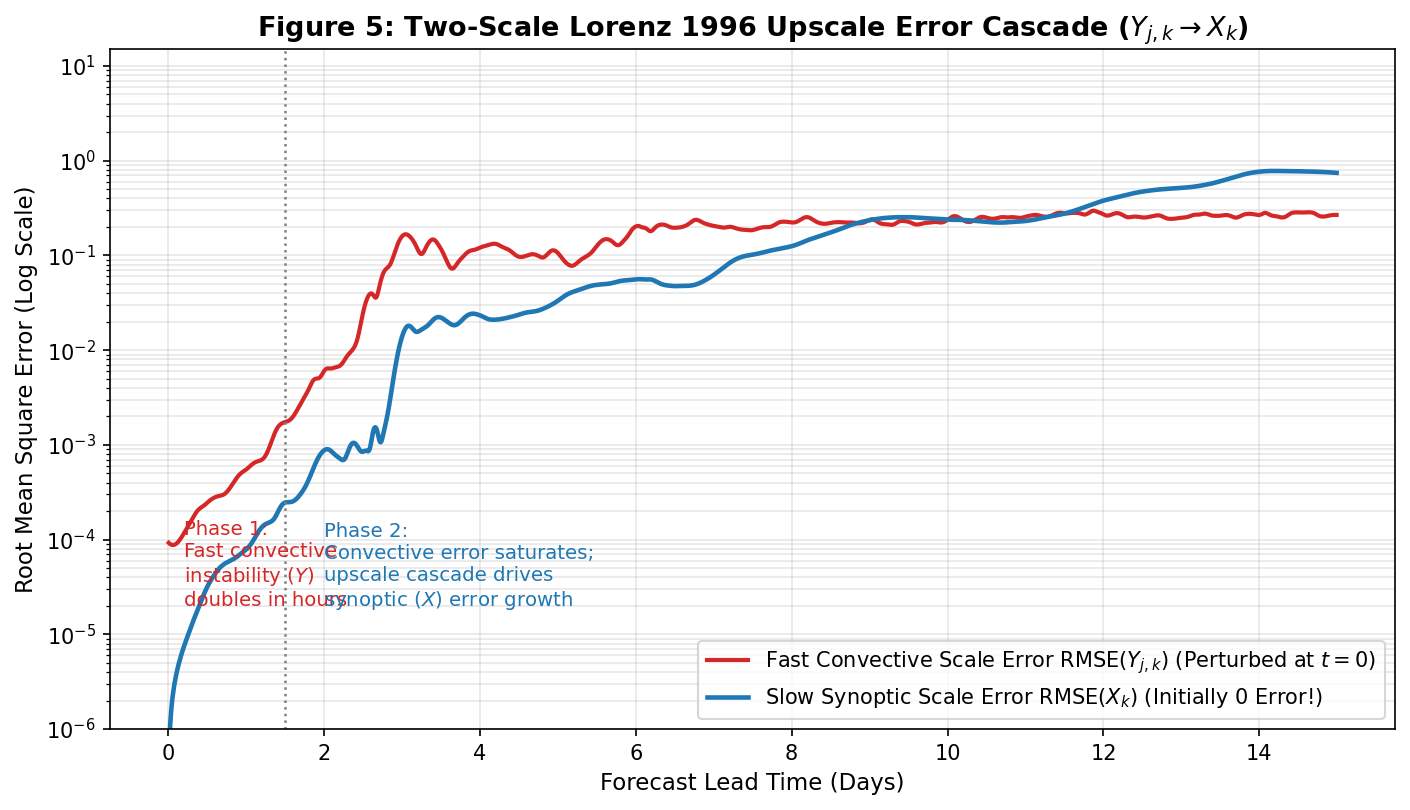

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Coupled L96 Parameters (Standard Lorenz 1996 two-scale setup)
K = 18       # Number of slow synoptic sectors
J = 10       # Number of fast convective variables per sector (180 total Y variables)
F = 10.0     # Synoptic forcing
h = 1.0      # Coupling strength
c = 10.0     # Time-scale ratio (Y evolves 10x faster than X)
b = 10.0     # Amplitude ratio (Y has 10x smaller amplitude than X)
dt = 0.002   # Small time step required to resolve fast convective scales

def coupled_l96_rhs(X, Y):
    """
    X has shape (K,)
    Y has shape (K * J,) arranged as a cyclic ring of fast variables
    """
    Y_reshaped = Y.reshape(K, J)
    Y_sum = np.sum(Y_reshaped, axis=1)
    
    # Slow synoptic scale evolution dX_k / dt
    dX = (np.roll(X, -1) - np.roll(X, 2)) * np.roll(X, 1) - X + F - (h * c / b) * Y_sum
    
    # Fast convective scale evolution dY_{j,k} / dt
    X_repeated = np.repeat(X, J)
    dY = c * b * np.roll(Y, -1) * (np.roll(Y, 1) - np.roll(Y, -2)) - c * Y + (h * c / b) * X_repeated
    return dX, dY

def coupled_rk4_step(X, Y, dt):
    k1_x, k1_y = coupled_l96_rhs(X, Y)
    k2_x, k2_y = coupled_l96_rhs(X + 0.5*dt*k1_x, Y + 0.5*dt*k1_y)
    k3_x, k3_y = coupled_l96_rhs(X + 0.5*dt*k2_x, Y + 0.5*dt*k2_y)
    k4_x, k4_y = coupled_l96_rhs(X + dt*k3_x, Y + dt*k3_y)
    
    X_next = X + (dt / 6.0) * (k1_x + 2*k2_x + 2*k3_x + k4_x)
    Y_next = Y + (dt / 6.0) * (k1_y + 2*k2_y + 2*k3_y + k4_y)
    return X_next, Y_next

# 1. Spin up the coupled system onto its multiscale attractor
np.random.seed(10)
X_true = F * np.ones(K)
X_true[0] += 0.1
Y_true = np.random.uniform(-0.1, 0.1, K * J)

print("Spinning up Two-Scale Coupled Lorenz 1996 model...")
for _ in range(2500):
    X_true, Y_true = coupled_rk4_step(X_true, Y_true, dt)

# 2. Initialize Perturbed Run:
# ZERO error in large-scale X_k; tiny 1e-4 perturbation ONLY in fast convective Y_{j,k}
X_pert = X_true.copy()
Y_pert = Y_true + np.random.normal(0, 1e-4, size=K * J)

n_steps = 1500  # 3.0 model units = 15 Atmospheric Days
days = np.arange(n_steps) * dt * 5.0

rmse_X = np.zeros(n_steps)
rmse_Y = np.zeros(n_steps)

print("Simulating upscale error cascade from convective Y to synoptic X...")
for t in range(n_steps):
    rmse_X[t] = np.sqrt(np.mean((X_pert - X_true)**2))
    rmse_Y[t] = np.sqrt(np.mean((Y_pert - Y_true)**2))
    
    X_true, Y_true = coupled_rk4_step(X_true, Y_true, dt)
    X_pert, Y_pert = coupled_rk4_step(X_pert, Y_pert, dt)

# --- Plot Figure 5 ---
plt.figure(figsize=(9.5, 5.5), dpi=150)

plt.semilogy(days[1:], rmse_Y[1:], color='#d62728', lw=2,
             label="Fast Convective Scale Error $\\text{RMSE}(Y_{j,k})$ (Perturbed at $t=0$)")
plt.semilogy(days[1:], rmse_X[1:], color='#1f77b4', lw=2.2,
             label="Slow Synoptic Scale Error $\\text{RMSE}(X_k)$ (Initially 0 Error!)")

# Annotate physical phases
plt.axvline(1.5, color='gray', linestyle=':', lw=1.2)
plt.text(0.2, 2e-5, "Phase 1:\nFast convective\ninstability ($Y$)\ndoubles in hours", fontsize=9.5, color='#d62728')
plt.text(2.0, 2e-5, "Phase 2:\nConvective error saturates;\nupscale cascade drives\nsynoptic ($X$) error growth", fontsize=9.5, color='#1f77b4')

plt.title("Figure 5: Two-Scale Lorenz 1996 Upscale Error Cascade ($Y_{j,k} \\rightarrow X_k$)", fontsize=13, fontweight='bold')
plt.xlabel("Forecast Lead Time (Days)", fontsize=11)
plt.ylabel("Root Mean Square Error (Log Scale)", fontsize=11)
plt.ylim(1e-6, 15)
plt.grid(True, which="both", alpha=0.3)
plt.legend(fontsize=10, loc='lower right')
plt.tight_layout()
# plt.savefig("Figure5_Coupled_L96_Upscale_Cascade.png")
plt.show()

<>:80: SyntaxWarning: invalid escape sequence '\d'
<>:80: SyntaxWarning: invalid escape sequence '\d'
C:\Users\KIIT\AppData\Local\Temp\ipykernel_19440\2413337056.py:80: SyntaxWarning: invalid escape sequence '\d'
  axs[0, 1].plot(lead_days, traj_pert[:, 19], color='#d62728', lw=1.8, linestyle='--', label="Forecast with Perturbation ($\delta_0 = 0.1$)")


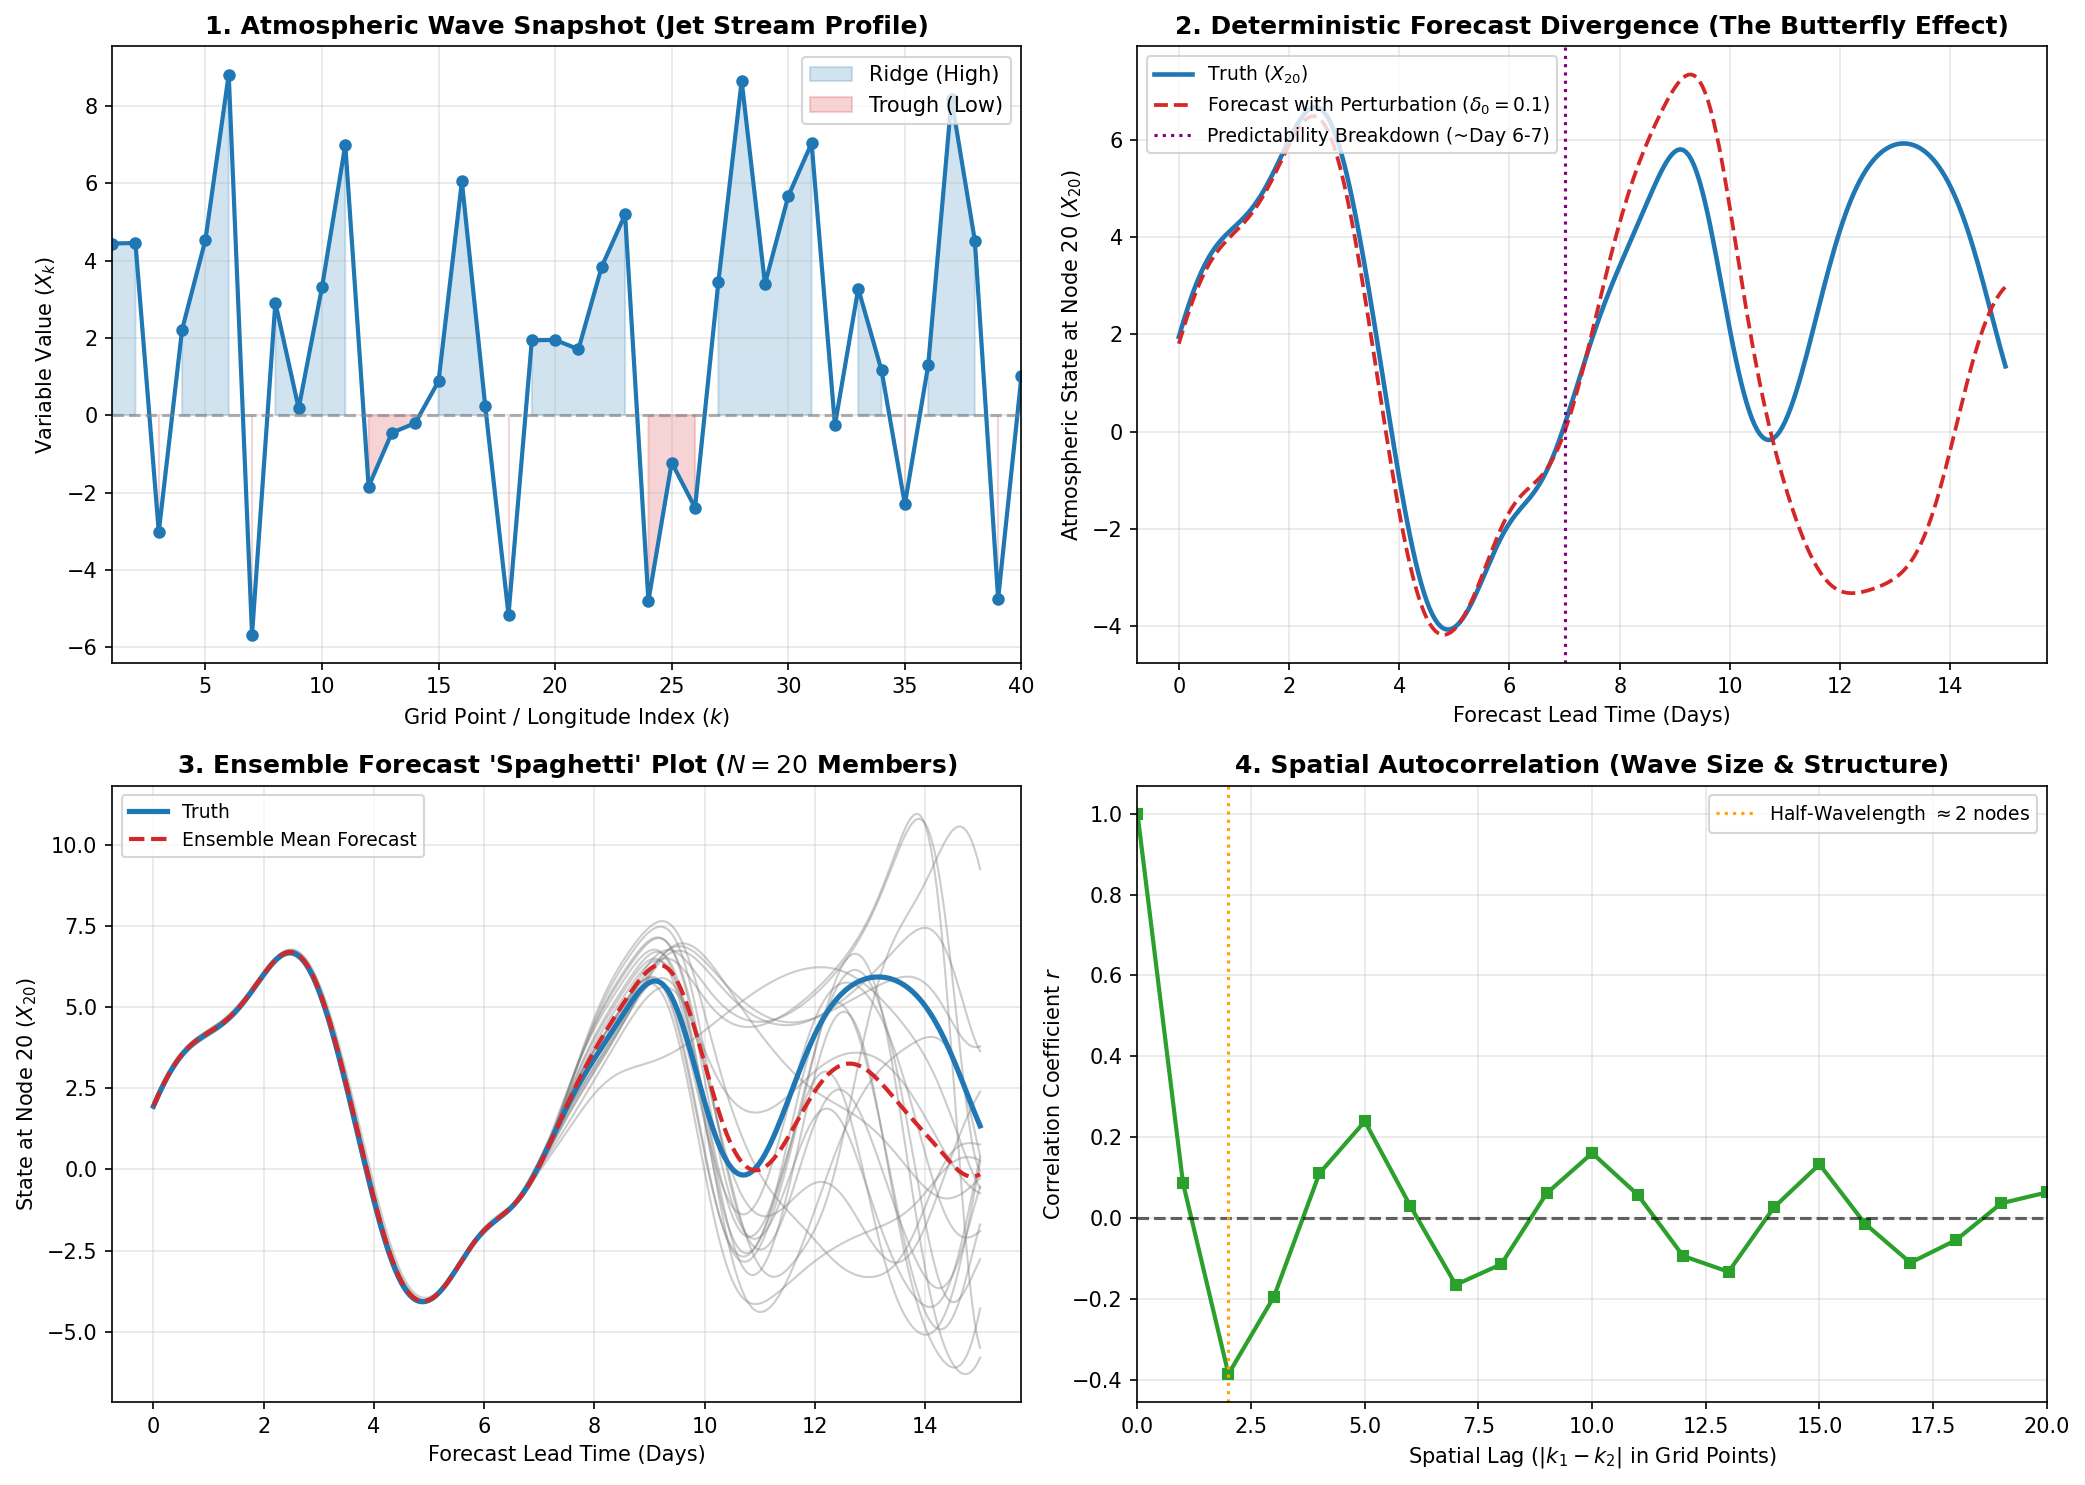

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Fast Vectorized RK4 Integrator for Lorenz 1996
# ---------------------------------------------------------
def l96_step(X, dt=0.01, F=8.0):
    """Vectorized single step for state array X of shape (..., K)."""
    def rhs(s):
        return (np.roll(s, -1, axis=-1) - np.roll(s, 2, axis=-1)) * np.roll(s, 1, axis=-1) - s + F
    k1 = rhs(X)
    k2 = rhs(X + 0.5 * dt * k1)
    k3 = rhs(X + 0.5 * dt * k2)
    k4 = rhs(X + dt * k3)
    return X + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

# Parameters
K = 40          # 40 longitude points around the globe
F = 8.0         # Standard chaotic forcing
dt = 0.01       # 0.01 model time = 0.05 days = 1.2 hours
days_per_step = dt * 5.0

# Spin-up to reach the chaotic attractor
np.random.seed(42)
x_state = F * np.ones(K)
x_state[0] += 0.01
for _ in range(1500):
    x_state = l96_step(x_state, dt, F)

# ---------------------------------------------------------
# Figure Setup (2x2 Grid)
# ---------------------------------------------------------
fig, axs = plt.subplots(2, 2, figsize=(14, 10), dpi=150)

# =========================================================
# Plot 1: Instantaneous Spatial Wave Profile (Snapshot)
# =========================================================
# Let it evolve for a few days
for _ in range(200):
    x_state = l96_step(x_state, dt, F)

grid_nodes = np.arange(1, K + 1)
axs[0, 0].plot(grid_nodes, x_state, 'o-', color='#1f77b4', lw=2, markersize=5)
axs[0, 0].axhline(0, color='gray', linestyle='--', alpha=0.6)
axs[0, 0].fill_between(grid_nodes, x_state, 0, where=(x_state >= 0), color='#1f77b4', alpha=0.2, label='Ridge (High)')
axs[0, 0].fill_between(grid_nodes, x_state, 0, where=(x_state < 0), color='#d62728', alpha=0.2, label='Trough (Low)')
axs[0, 0].set_title("1. Atmospheric Wave Snapshot (Jet Stream Profile)", fontweight='bold')
axs[0, 0].set_xlabel("Grid Point / Longitude Index ($k$)")
axs[0, 0].set_ylabel("Variable Value ($X_k$)")
axs[0, 0].set_xlim(1, K)
axs[0, 0].legend(loc='upper right')
axs[0, 0].grid(True, alpha=0.3)

# =========================================================
# Plot 2: Sensitive Dependence / Divergence (The Butterfly Effect)
# =========================================================
n_steps = 300  # 15 forecast days
lead_days = np.arange(n_steps + 1) * days_per_step

# True vs Perturbed run (delta = 0.01 at a single node)
traj_true = np.zeros((n_steps + 1, K))
traj_pert = np.zeros((n_steps + 1, K))

x_true = x_state.copy()
x_pert = x_state.copy()
# x_pert[19] += 0.01  # Perturb node 20 slightly
x_pert = x_state + np.random.normal(0, 0.1, size=K)

traj_true[0] = x_true
traj_pert[0] = x_pert

for t in range(1, n_steps + 1):
    x_true = l96_step(x_true, dt, F)
    x_pert = l96_step(x_pert, dt, F)
    traj_true[t] = x_true
    traj_pert[t] = x_pert

# Plot single site X_20 over time
axs[0, 1].plot(lead_days, traj_true[:, 19], color='#1f77b4', lw=2.2, label="Truth ($X_{20}$)")
axs[0, 1].plot(lead_days, traj_pert[:, 19], color='#d62728', lw=1.8, linestyle='--', label="Forecast with Perturbation ($\delta_0 = 0.1$)")
axs[0, 1].axvline(7.0, color='purple', linestyle=':', lw=1.5, label="Predictability Breakdown (~Day 6-7)")
axs[0, 1].set_title("2. Deterministic Forecast Divergence (The Butterfly Effect)", fontweight='bold')
axs[0, 1].set_xlabel("Forecast Lead Time (Days)")
axs[0, 1].set_ylabel("Atmospheric State at Node 20 ($X_{20}$)")
axs[0, 1].legend(loc='upper left', fontsize=9)
axs[0, 1].grid(True, alpha=0.3)

# =========================================================
# Plot 3: Ensemble "Spaghetti" Plot (Operational Forecasting)
# =========================================================
n_members = 20
ensemble = np.repeat(traj_true[0:1], n_members, axis=0)
# Add small random noise to each member
ensemble += np.random.normal(0, 0.05, size=ensemble.shape)

ens_trajectories = np.zeros((n_steps + 1, n_members))
ens_trajectories[0] = ensemble[:, 19]

curr_ens = ensemble.copy()
for t in range(1, n_steps + 1):
    curr_ens = l96_step(curr_ens, dt, F)
    ens_trajectories[t] = curr_ens[:, 19]

# Plot each member as a faint grey line
for m in range(n_members):
    axs[1, 0].plot(lead_days, ens_trajectories[:, m], color='gray', alpha=0.4, lw=1)
# Plot truth and ensemble mean
axs[1, 0].plot(lead_days, traj_true[:, 19], color='#1f77b4', lw=2.5, label="Truth")
axs[1, 0].plot(lead_days, np.mean(ens_trajectories, axis=1), color='#d62728', lw=2, linestyle='--', label="Ensemble Mean Forecast")
axs[1, 0].set_title("3. Ensemble Forecast 'Spaghetti' Plot ($N=20$ Members)", fontweight='bold')
axs[1, 0].set_xlabel("Forecast Lead Time (Days)")
axs[1, 0].set_ylabel("State at Node 20 ($X_{20}$)")
axs[1, 0].legend(loc='upper left', fontsize=9)
axs[1, 0].grid(True, alpha=0.3)

# =========================================================
# Plot 4: Spatial Autocorrelation Function (Wave Scale)
# =========================================================
# Compute correlation between X_k and X_{k + lag} across time
long_run_steps = 1000
spatial_data = np.zeros((long_run_steps, K))
curr_s = x_true.copy()
for t in range(long_run_steps):
    curr_s = l96_step(curr_s, dt, F)
    spatial_data[t] = curr_s

# Subtract temporal mean per node
anom = spatial_data - np.mean(spatial_data, axis=0)

lags = np.arange(K // 2 + 1)
autocorr = np.zeros(len(lags))
var_total = np.var(anom)

for i, lag in enumerate(lags):
    rolled = np.roll(anom, -lag, axis=1)
    autocorr[i] = np.mean(anom * rolled) / var_total

axs[1, 1].plot(lags, autocorr, 's-', color='#2ca02c', lw=2, markersize=5)
axs[1, 1].axhline(0, color='black', linestyle='--', alpha=0.6)
# First negative trough indicates half-wavelength
min_lag = lags[np.argmin(autocorr)]
axs[1, 1].axvline(min_lag, color='orange', linestyle=':', lw=1.5, label=f"Half-Wavelength $\\approx {min_lag}$ nodes")
axs[1, 1].set_title("4. Spatial Autocorrelation (Wave Size & Structure)", fontweight='bold')
axs[1, 1].set_xlabel("Spatial Lag ($|k_1 - k_2|$ in Grid Points)")
axs[1, 1].set_ylabel("Correlation Coefficient $r$")
axs[1, 1].set_xlim(0, K // 2)
axs[1, 1].legend(loc='upper right', fontsize=9)
axs[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig("L96_Simpler_Dynamics_and_Predictability_Plots.png")
plt.show()

Spinning up onto the chaotic attractor...
Generating phase-space trajectory...


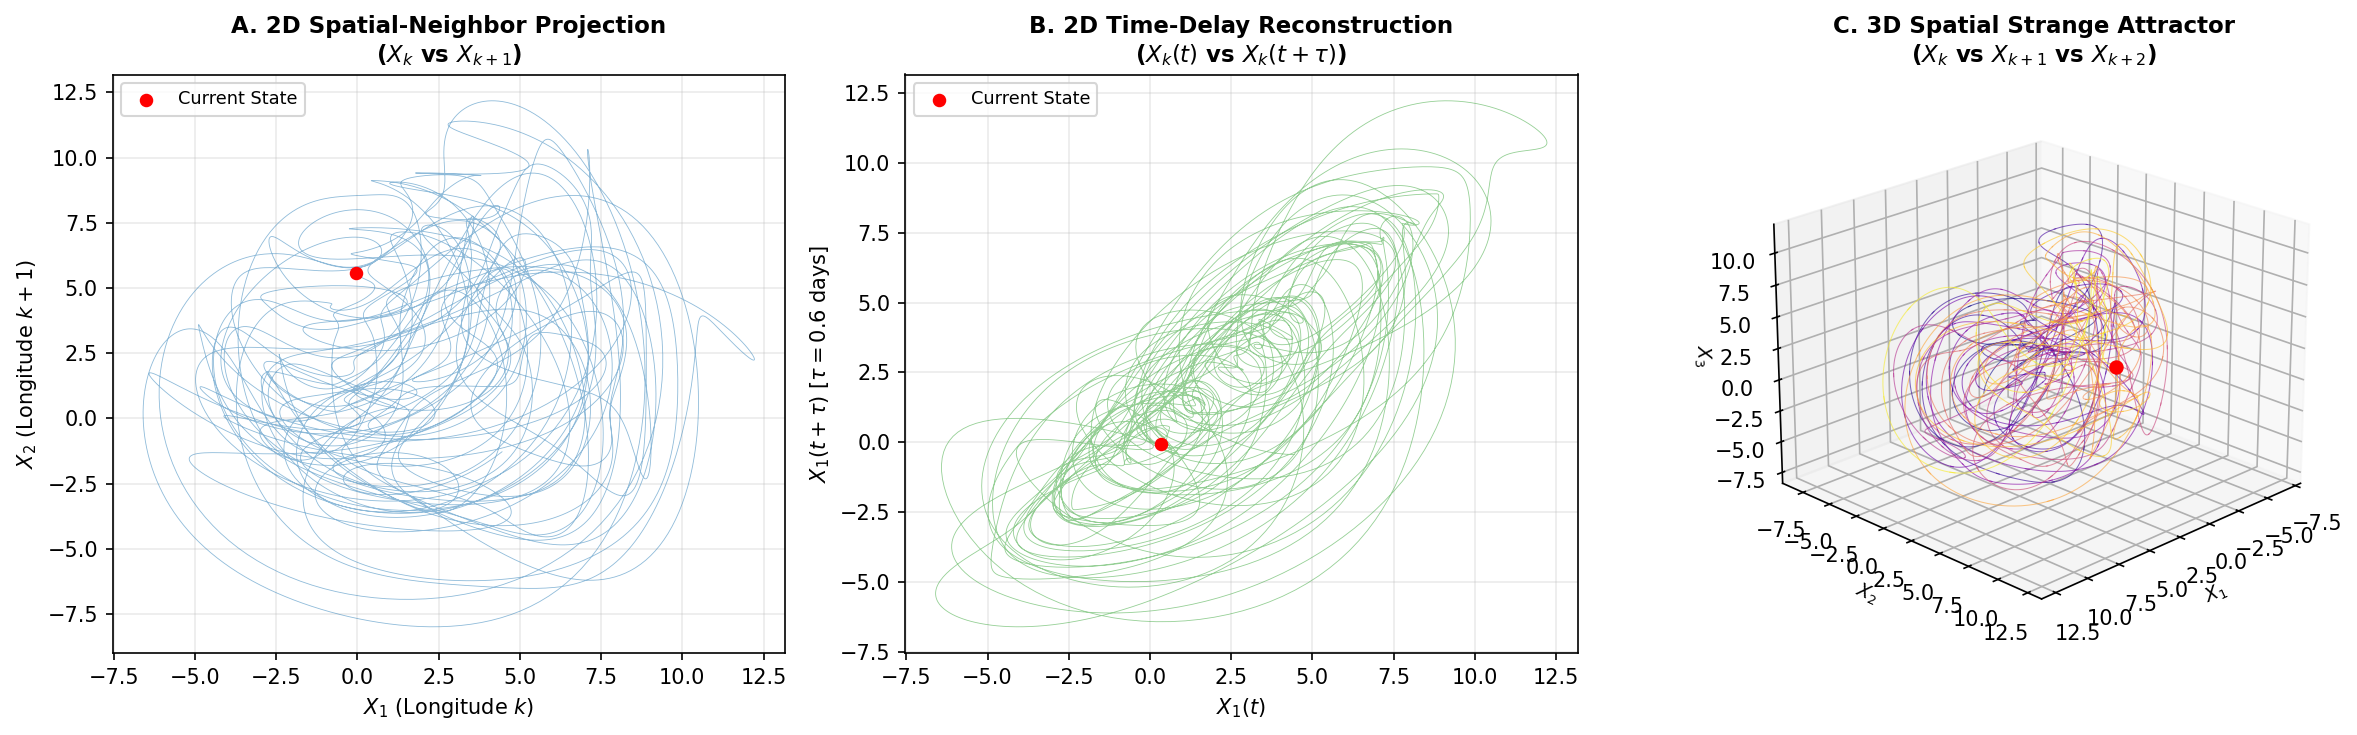

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# -------------------------------------------------------------
# 1. Fast Vectorized RK4 Integrator for Lorenz 1996
# -------------------------------------------------------------
def l96_step(x, dt=0.01, F=8.0):
    def rhs(s):
        return (np.roll(s, -1) - np.roll(s, 2)) * np.roll(s, 1) - s + F
    k1 = rhs(x)
    k2 = rhs(x + 0.5 * dt * k1)
    k3 = rhs(x + 0.5 * dt * k2)
    k4 = rhs(x + dt * k3)
    return x + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

# -------------------------------------------------------------
# 2. Simulation Setup & Spin-Up
# -------------------------------------------------------------
K = 40
F = 8.0
dt = 0.005          # Finer step for smooth continuous orbit trails
n_steps = 12000      # Trajectory length (~60 model time units = 300 days)

# Initialize and discard transients onto the attractor
np.random.seed(42)
x = F * np.ones(K)
x[0] += 0.01

print("Spinning up onto the chaotic attractor...")
for _ in range(2000):
    x = l96_step(x, dt, F)

# Record trajectory history
print("Generating phase-space trajectory...")
traj = np.zeros((n_steps, K))
for step in range(n_steps):
    x = l96_step(x, dt, F)
    traj[step] = x

# Pick reference node k (arbitrary due to spatial cyclic symmetry)
k = 0
x_k = traj[:, k]
x_next = traj[:, (k + 1) % K]
x_next2 = traj[:, (k + 2) % K]

# Time delay lag tau (approx. 1/4 of dominant wave period, ~25 steps = 0.125 time units)
tau_steps = 25
x_tau = traj[tau_steps:, k]
x_base = traj[:-tau_steps, k]

# -------------------------------------------------------------
# 3. Plotting: 2D & 3D Phase-Space Reconstructions
# -------------------------------------------------------------
fig = plt.figure(figsize=(16, 5), dpi=150)

# --- Panel 1: 2D Spatial Neighbor Projection (X_k vs X_{k+1}) ---
ax1 = fig.add_subplot(1, 3, 1)
# Subsample slightly for clean line drawing without heavy overlap
step_sub = 1
ax1.plot(x_k[::step_sub], x_next[::step_sub], color='#1f77b4', lw=0.4, alpha=0.5)
ax1.scatter(x_k[-1], x_next[-1], color='red', s=30, zorder=5, label='Current State')
ax1.set_title("A. 2D Spatial-Neighbor Projection\n($X_k$ vs $X_{k+1}$)", fontsize=11, fontweight='bold')
ax1.set_xlabel(f"$X_{{{k+1}}}$ (Longitude $k$)", fontsize=10)
ax1.set_ylabel(f"$X_{{{k+2}}}$ (Longitude $k+1$)", fontsize=10)
ax1.grid(True, alpha=0.25)
ax1.legend(loc='upper left', fontsize=8.5)

# --- Panel 2: 2D Time-Delay Embedding (Takens' Theorem) ---
ax2 = fig.add_subplot(1, 3, 2)
ax2.plot(x_base[::step_sub], x_tau[::step_sub], color='#2ca02c', lw=0.4, alpha=0.5)
ax2.scatter(x_base[-1], x_tau[-1], color='red', s=30, zorder=5, label='Current State')
ax2.set_title("B. 2D Time-Delay Reconstruction\n($X_k(t)$ vs $X_k(t + \\tau)$)", fontsize=11, fontweight='bold')
ax2.set_xlabel(f"$X_{{{k+1}}}(t)$", fontsize=10)
ax2.set_ylabel(f"$X_{{{k+1}}}(t + \\tau)$ [$\\tau = {tau_steps*dt*5.0:.1f}$ days]", fontsize=10)
ax2.grid(True, alpha=0.25)
ax2.legend(loc='upper left', fontsize=8.5)

# --- Panel 3: 3D Spatial Neighbor Strange Attractor ---
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
# Color by coordinate depth to give 3D depth perception
colors = plt.cm.plasma(np.linspace(0, 1, len(x_k)))

# Draw continuous trail using small segments for gradient coloring
for i in range(0, len(x_k) - 20, 20):
    ax3.plot(x_k[i:i+22], x_next[i:i+22], x_next2[i:i+22], 
             color=colors[i], lw=0.5, alpha=0.6)

ax3.scatter([x_k[-1]], [x_next[-1]], [x_next2[-1]], color='red', s=35, label='Current State')
ax3.set_title("C. 3D Spatial Strange Attractor\n($X_k$ vs $X_{k+1}$ vs $X_{k+2}$)", fontsize=11, fontweight='bold')
ax3.set_xlabel(f"$X_{{{k+1}}}$", fontsize=9, labelpad=0)
ax3.set_ylabel(f"$X_{{{k+2}}}$", fontsize=9, labelpad=0)
ax3.set_zlabel(f"$X_{{{k+3}}}$", fontsize=9, labelpad=0)
ax3.view_init(elev=22, azim=45)
ax3.grid(True, alpha=0.2)

plt.tight_layout()
# plt.savefig("L96_Phase_Space_Attractor_Reconstructions.png")
plt.show()

Simulating error growth across perturbation scales...


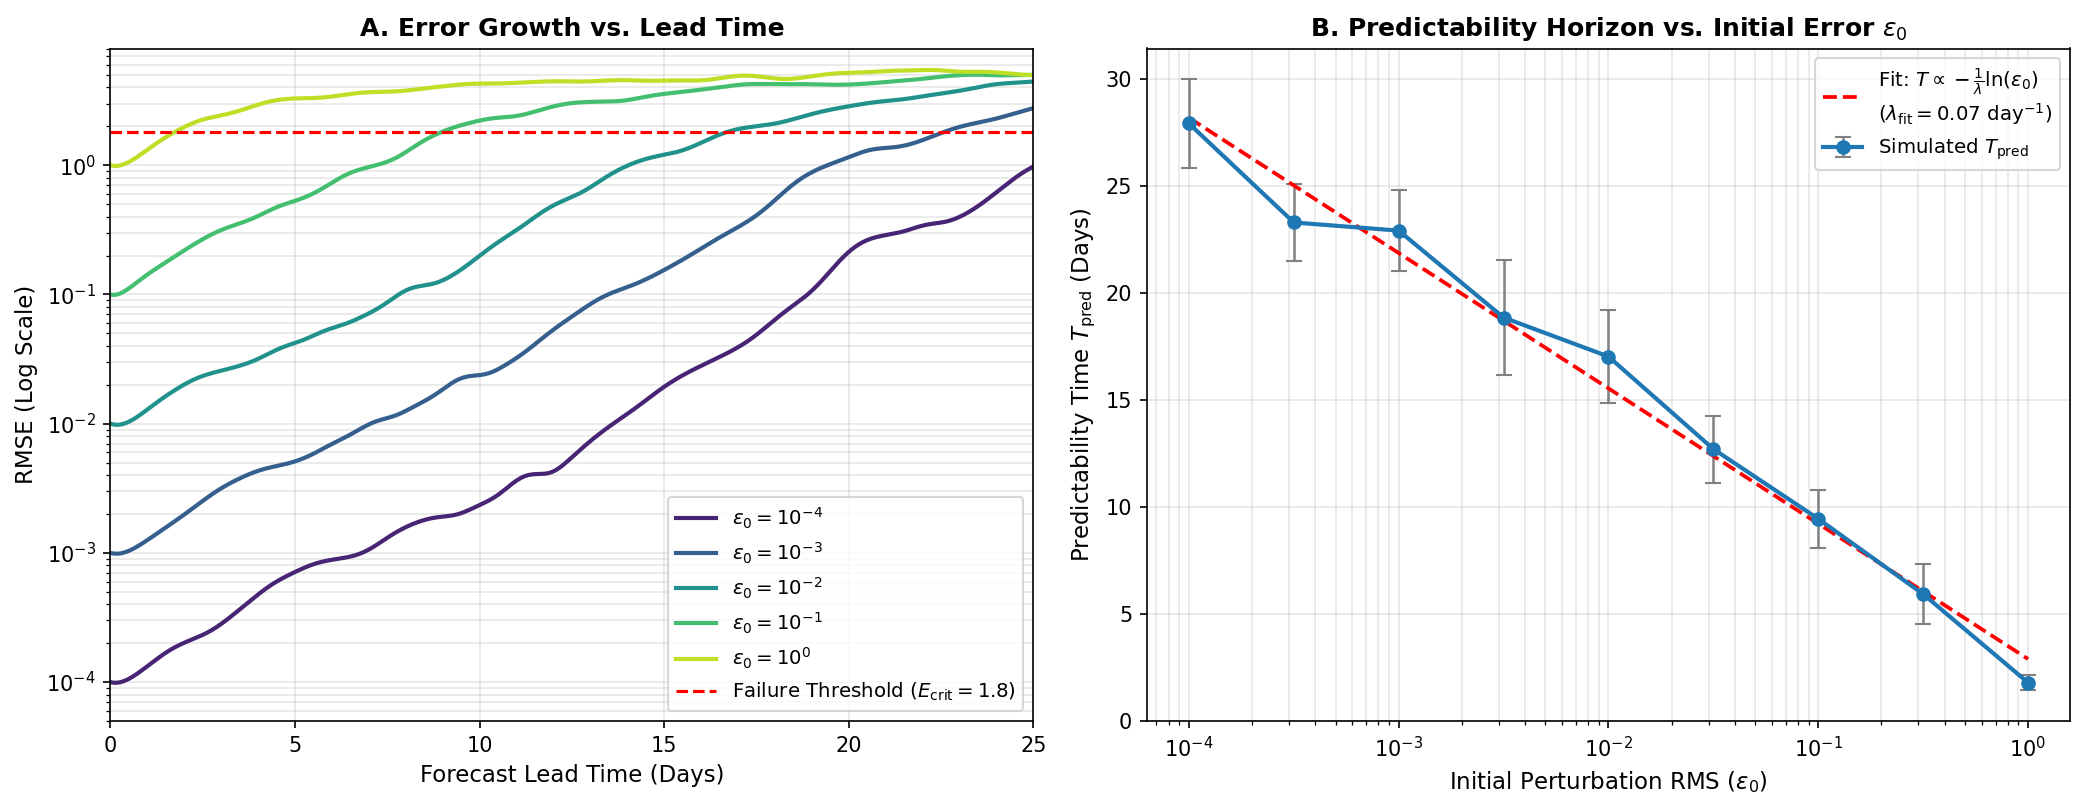

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 1. Lorenz 1996 Vectorized RK4 Integrator
# -------------------------------------------------------------------------
def l96_step(X, dt=0.01, F=8.0):
    def rhs(s):
        return (np.roll(s, -1, axis=-1) - np.roll(s, 2, axis=-1)) * np.roll(s, 1, axis=-1) - s + F
    k1 = rhs(X)
    k2 = rhs(X + 0.5 * dt * k1)
    k3 = rhs(X + 0.5 * dt * k2)
    k4 = rhs(X + dt * k3)
    return X + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

K = 40
F = 8.0
dt = 0.01
days_per_step = dt * 5.0  # 1 model unit = 5 days -> 0.05 days/step

# Spin-up to settle onto the chaotic attractor
np.random.seed(42)
x_state = F * np.ones(K)
x_state[0] += 0.01
for _ in range(1500):
    x_state = l96_step(x_state, dt, F)

# -------------------------------------------------------------------------
# 2. Experiment Setup: Sweep Perturbations
# -------------------------------------------------------------------------
n_steps = 600  # 30 forecast days
lead_days = np.arange(n_steps + 1) * days_per_step

# Error failure threshold: when RMSE reaches 50% of climatological std dev
# For L96 at F=8, sigma_clim ~ 3.6, so E_crit ~ 1.8
E_crit = 1.8

# Sweep initial perturbation amplitudes from 10^-4 to 1.0
epsilons = np.logspace(-4, 0, 9)
n_realizations = 15  # average over realizations to smooth out local phase noise

pred_times = []
pred_stds = []
sample_rmse_curves = {}

print("Simulating error growth across perturbation scales...")
for eps in epsilons:
    times_for_eps = []
    avg_rmse = np.zeros(n_steps + 1)
    
    for r in range(n_realizations):
        # Generate truth trajectory
        truth = np.zeros((n_steps + 1, K))
        pert = np.zeros((n_steps + 1, K))
        
        # Advance truth slightly so each realization tests a different atmospheric state
        x_base = l96_step(x_state, dt, F)
        x_state = x_base.copy()
        
        # Add isotropic perturbation
        noise = np.random.normal(0, 1, size=K)
        noise = noise / np.linalg.norm(noise) * eps * np.sqrt(K)  # ensures RMS(noise) = eps
        
        xt = x_base.copy()
        xp = x_base + noise
        
        truth[0] = xt
        pert[0] = xp
        
        for t in range(1, n_steps + 1):
            xt = l96_step(xt, dt, F)
            xp = l96_step(xp, dt, F)
            truth[t] = xt
            pert[t] = xp
            
        rmse = np.sqrt(np.mean((pert - truth)**2, axis=1))
        avg_rmse += rmse / n_realizations
        
        # Find first crossing time of E_crit
        cross_idx = np.where(rmse >= E_crit)[0]
        if len(cross_idx) > 0:
            times_for_eps.append(lead_days[cross_idx[0]])
        else:
            times_for_eps.append(lead_days[-1])
            
    sample_rmse_curves[eps] = avg_rmse
    pred_times.append(np.mean(times_for_eps))
    pred_stds.append(np.std(times_for_eps))

# -------------------------------------------------------------------------
# 3. Plotting
# -------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)

# Panel 1: Error Growth Curves for Selected Perturbations
plot_eps_keys = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(plot_eps_keys)))

for eps, col in zip(plot_eps_keys, colors):
    # Find closest evaluated epsilon
    actual_eps = epsilons[np.argmin(np.abs(epsilons - eps))]
    ax1.semilogy(lead_days, sample_rmse_curves[actual_eps], color=col, lw=2,
                 label=f"$\\epsilon_0 = 10^{{{int(np.round(np.log10(eps)))}}}$")

ax1.axhline(E_crit, color='red', linestyle='--', lw=1.5, label=f"Failure Threshold ($E_{{\\text{{crit}}}} = {E_crit}$)")
ax1.set_title("A. Error Growth vs. Lead Time", fontsize=12, fontweight='bold')
ax1.set_xlabel("Forecast Lead Time (Days)", fontsize=11)
ax1.set_ylabel("RMSE (Log Scale)", fontsize=11)
ax1.set_ylim(5e-5, 8)
ax1.set_xlim(0, 25)
ax1.grid(True, which="both", alpha=0.3)
ax1.legend(loc='lower right', fontsize=9.5)

# Panel 2: Predictability Time vs. Initial Perturbation Size
log_eps = np.log(epsilons)
slope, intercept = np.polyfit(log_eps, pred_times, 1)

ax2.errorbar(epsilons, pred_times, yerr=pred_stds, fmt='o-', color='#1f77b4',
             ecolor='gray', elinewidth=1.2, capsize=4, lw=2, markersize=6, label="Simulated $T_{\\text{pred}}$")

# Fit line: T_pred = slope * ln(eps) + intercept
fit_curve = slope * np.log(epsilons) + intercept
ax2.plot(epsilons, fit_curve, 'r--', lw=1.8, 
         label=f"Fit: $T \\propto -\\frac{{1}}{{\\lambda}}\\ln(\\epsilon_0)$\n($\\lambda_{{\\text{{fit}}}} = {-1/slope / 5.0:.2f}\\text{{ day}}^{{-1}}$)")

ax2.set_xscale('log')
ax2.set_title("B. Predictability Horizon vs. Initial Error $\\epsilon_0$", fontsize=12, fontweight='bold')
ax2.set_xlabel("Initial Perturbation RMS ($\\epsilon_0$)", fontsize=11)
ax2.set_ylabel("Predictability Time $T_{\\text{pred}}$ (Days)", fontsize=11)
ax2.grid(True, which="both", alpha=0.3)
ax2.legend(loc='upper right', fontsize=9.5)

plt.tight_layout()
# plt.savefig("L96_Predictability_Time_vs_Perturbation.png")
plt.show()